# Level 5 — Noise and space

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/05_noise-and-space.ipynb)

Models with random inputs and models extended in space. XPP integrates
stochastic differential equations (white noise with `wiener`), switches
discrete Markov variables at random (`markov`), and writes chains of coupled
cells compactly with arrays. Random runs are made reproducible by fixing XPP's
seed, and their numbers are checked against exact values within the
statistical error of the runs.

| | model | what it shows |
|---|---|---|
| [26](#noisy-fhn-sde) | FitzHugh–Nagumo with white noise | coherence resonance (seeded, reproducible) |
| [27](#telegraph-fhn-markov) | FitzHugh–Nagumo with a Markov input | dwell times, fraction on, firing only when on |
| [28](#fhn-chain-arrays) | chain of 20 FitzHugh–Nagumo cells | travelling spikes, speed $\propto \sqrt{d}$ |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 26–28 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT and its AUTO
through pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="noisy-fhn-sde"></a>
## 26. Noisy FitzHugh–Nagumo: coherence resonance

FitzHugh–Nagumo in its excitable regime, with white noise $\xi(t)$ added to
the slow variable:

$$
\varepsilon\,\dot v = v - \frac{v^3}{3} - u, \qquad \dot u = v + a + \sigma\,\xi(t),
$$

with $\varepsilon = 0.05$, $a = 1.05$ and the noise strength $\sigma$. The
noise is XPP's `wiener` variable, integrated by the Euler–Maruyama method.
With $a > 1$ the rest state is stable and nothing happens without noise.
Noise alone makes the cell fire, and at a moderate noise level the spikes are
at their most regular: *coherence resonance* (Pikovsky and Kurths, 1997).

We check the rest state, look at noise-driven spike trains, and sweep $\sigma$:
the spike rate rises steadily, while the coefficient of variation (CV) of the
inter-spike intervals has a minimum inside the sweep.

In [3]:
section("26_noisy-fhn-sde")

### The model

`wiener("w")` declares the white-noise variable. The run uses Euler's method
with $dt = 0.002$. XPP's random seed is fixed (*Numerics → stocHast → New
seed*): the same seed gives the same noise and the same numbers every time.
XPP's Jacobian (for eigenvalues) uses finite differences with step `jac_eps`,
$10^{-3}$ by default, which shifts the eigenvalues by about 1%; we set it
after loading, since XPP ignores `@ jac_eps` in the file.

Spikes are counted by `spike_times`: the times where $v$ rises through 1,
counted again only after $v$ has fallen below $-1$, so that noisy wiggles
around the threshold are not counted twice.

In [4]:
SEED = 1
mb = (ModelBuilder("noisy_fhn")
      .comment("FitzHugh-Nagumo with white noise on the recovery variable")
      .wiener("w")
      .ode("v", "(v-v^3/3-u)/eps")
      .ode("u", "v+a+sig*w")
      .parameter(eps=0.05, a=1.05, sig=0.2)
      .initial(v=-1.05, u=-0.664)
      .option(meth="euler", dt=0.002, total=60))
print(mb.render())
m = mb.load(ODE)
m.buttons.numerics.stochast.new_seed(SEED)
m.set(jac_eps=1e-8)


def spike_times(tr):
    v, t = tr["v"], tr.t
    up = np.flatnonzero((v[:-1] < 1) & (v[1:] >= 1)) + 1
    down = np.flatnonzero((v[:-1] > -1) & (v[1:] <= -1)) + 1
    keep = [i for j, i in enumerate(up)
            if j == 0 or np.any((down > up[j - 1]) & (down < i))]
    return t[keep]

# FitzHugh-Nagumo with white noise on the recovery variable
wiener w
v'=(v-v^3/3-u)/eps
u'=v+a+sig*w
par eps=0.05,a=1.05,sig=0.2
init v=-1.05,u=-0.664
@ meth=euler,dt=0.002,total=60
done



### No noise: a stable rest state, no spikes

The equilibrium with its eigenvalues, and a noise-free run of 500 time units
started a little off rest: it returns to rest without a single spike.

In [5]:
eps, a = 0.05, 1.05
eq = m.equilibrium({"v": -1, "u": -0.7})
print("equilibrium:", eq, "\n  eigenvalues:", np.round(eq.eigenvalues, 5))
quiet = m.run(keep=False, sig=0, total=500, v=-0.9)
n_quiet = len(spike_times(quiet))
print(f"spikes in 500 time units without noise: {n_quiet}")

equilibrium: <Equilibrium stable V=-1.05, U=-0.664125> 
  eigenvalues: [-1.025+4.35309j -1.025-4.35309j]


spikes in 500 time units without noise: 0


### Spike trains, and a noisy orbit in the phase plane

Three noise levels: weak noise gives rare, irregular spikes; moderate noise a
fairly regular train; strong noise an irregular one again. In the phase plane
the noisy orbit wanders around the rest state and now and then escapes along
the cubic nullcline. The nullclines are drawn for the noise-free system
($\sigma = 0$, since $w$ holds the last noise sample).

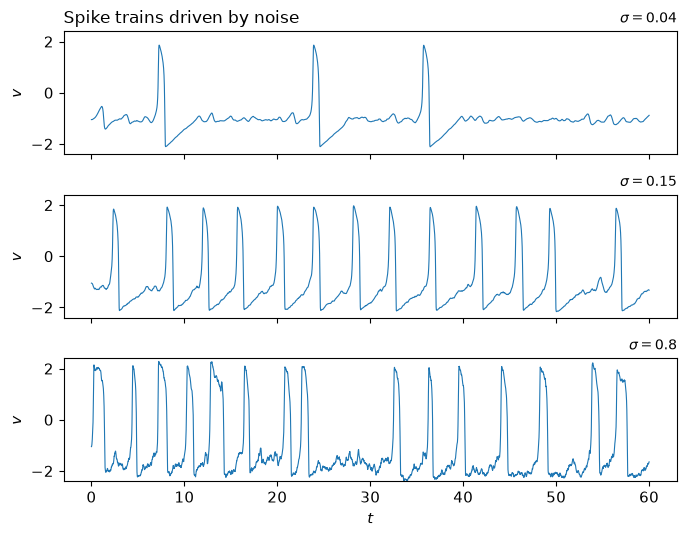

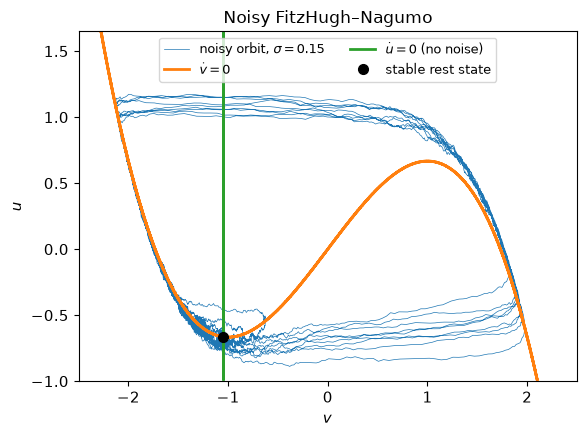

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(7, 5.5), sharex=True)
for ax, s in zip(axs, (0.04, 0.15, 0.8)):
    tr = m.run(keep=False, sig=s, total=60)
    ax.plot(tr.t, tr["v"], lw=0.8)
    ax.set(ylabel="$v$", ylim=(-2.4, 2.4))
    ax.set_title(rf"$\sigma = {s}$", loc="right", fontsize=10)
axs[0].set_title("Spike trains driven by noise", loc="left")
axs[-1].set_xlabel("$t$")
fig.tight_layout()
fig.savefig(FIG / "spike_trains.png")

tr = m.run(keep=False, sig=0.15, total=40)
m.pars["sig"] = 0
nc = m.nullclines(x="v", y="u", xlo=-2.5, xhi=2.5, ylo=-1, yhi=1.65, mesh=200)
m.pars["sig"] = 0.2
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(tr["v"], tr["u"], lw=0.5, color="tab:blue", label=r"noisy orbit, $\sigma = 0.15$")
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:orange", lw=2, label=r"$\dot v = 0$")
ax.plot(nc["U"][:, 0], nc["U"][:, 1], color="tab:green", lw=2, label=r"$\dot u = 0$ (no noise)")
ax.plot(eq.x["V"], eq.x["U"], "ko", ms=7, label="stable rest state")
ax.set(xlim=(-2.5, 2.5), ylim=(-1, 1.65), xlabel="$v$", ylabel="$u$", title="Noisy FitzHugh–Nagumo")
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### Sweep the noise: rate and CV of the inter-spike intervals

For each $\sigma$, a run of 4000 time units gives $n$ inter-spike intervals
with mean $\bar T$ and coefficient of variation $c = \mathrm{std}/\bar T$.
The rate is $1/\bar T$, with standard error $c/(\bar T\sqrt n)$; the
large-sample standard error of a CV is

$$
\mathrm{se}(c) = c\,\sqrt{\frac{1 + 2c^2}{2n}} .
$$

  sig   spikes    rate     CV


  0.03     166  0.0416  0.741


  0.05     493  0.1231  0.579


  0.07     660  0.1648  0.401


  0.10     743  0.1856  0.326


  0.15     803  0.2009  0.296


  0.20     862  0.2155  0.272


  0.30     907  0.2267  0.291


  0.45     925  0.2311  0.379


  0.65     984  0.2459  0.409


  1.00    1015  0.2536  0.506


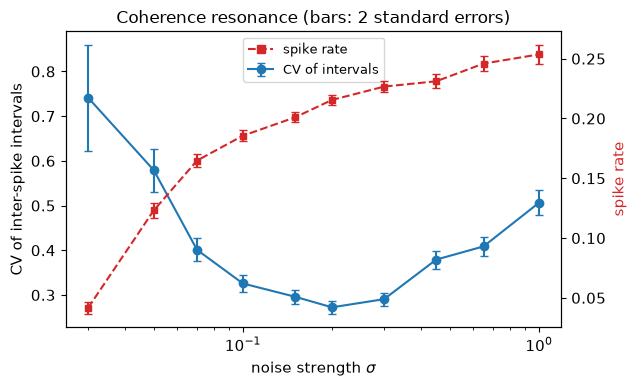

In [7]:
TOTAL = 4000
sigs = np.array([0.03, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3, 0.45, 0.65, 1.0])
rate, rate_se, cv, cv_se = [], [], [], []
print("  sig   spikes    rate     CV")
for s in sigs:
    isi = np.diff(spike_times(m.run(keep=False, sig=s, total=TOTAL)))
    n, c = len(isi), isi.std() / isi.mean()
    rate.append(1 / isi.mean()); rate_se.append(c / isi.mean() / np.sqrt(n))
    cv.append(c); cv_se.append(c * np.sqrt((1 + 2 * c**2) / (2 * n)))
    print(f"  {s:4.2f}  {n + 1:6d}  {rate[-1]:.4f}  {c:.3f}")
rate, rate_se, cv, cv_se = map(np.array, (rate, rate_se, cv, cv_se))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(sigs, cv, 2 * cv_se, fmt="o-", color="tab:blue", capsize=3, label="CV of intervals")
ax.set(xscale="log", xlabel=r"noise strength $\sigma$", ylabel="CV of inter-spike intervals")
ax.set_title("Coherence resonance (bars: 2 standard errors)")
ax2 = ax.twinx()
ax2.errorbar(sigs, rate, 2 * rate_se, fmt="s--", color="tab:red", capsize=3, ms=4)
ax2.set_ylabel("spike rate", color="tab:red")
ax.plot([], [], "s--", color="tab:red", label="spike rate")
ax.legend(loc="upper center")
fig.tight_layout()
fig.savefig(FIG / "coherence_resonance.png")

### Checks

* The rest state: $\dot v = 0$ and $\dot u = 0$ give
  $v^* = -a$ and $u^* = v^* - (v^*)^3/3 = -a + a^3/3$.
* Its Jacobian is

$$
J = \begin{pmatrix} (1 - v^2)/\varepsilon & -1/\varepsilon \\ 1 & 0 \end{pmatrix},
$$

  so the sum of the eigenvalues is $\mathrm{tr}\,J = (1 - a^2)/\varepsilon = -2.05 < 0$
  and their product $\det J = 1/\varepsilon > 0$: the rest state is stable,
  and without noise there are no spikes.
* Coherence resonance: the smallest CV lies inside the sweep, below the CV at
  both ends by more than 4 combined standard errors (the intervals of a
  noise-driven train are nearly independent).
* The rate never drops by more than 4 standard errors from one $\sigma$ to the
  next, and rises by more than 4 standard errors from the smallest to the
  largest $\sigma$.

In [8]:
check("rest state v = -a (exact)", eq.x["V"], -a, 1e-6)
check("rest state u = -a + a^3/3 (exact)", eq.x["U"], -a + a**3 / 3, 1e-6)
check("sum of eigenvalues (1-a^2)/eps (exact)", float(np.sum(eq.eigenvalues).real), (1 - a**2) / eps, 1e-4)
check("product of eigenvalues 1/eps (exact)", float(np.prod(eq.eigenvalues).real), 1 / eps, 1e-3)
check("spikes without noise", n_quiet, 0, 0)
k = int(np.argmin(cv))
gap = min(cv[0] - cv[k] - 4 * np.hypot(cv_se[0], cv_se[k]),
          cv[-1] - cv[k] - 4 * np.hypot(cv_se[-1], cv_se[k]))
print(f"  CV is smallest at sig = {sigs[k]}")
check("CV minimum inside, clear of both ends (1 = yes)", float(0 < k < len(sigs) - 1 and gap > 0), 1, 0)
drops = (rate[:-1] - rate[1:]) / np.hypot(rate_se[:-1], rate_se[1:])
check("rate never drops significantly (1 = yes)", float(drops.max() < 4), 1, 0)
check("rate rises from smallest to largest sig, in s.e. (> 4)",
      float((rate[-1] - rate[0]) / np.hypot(rate_se[0], rate_se[-1]) > 4), 1, 0)
checks_done()

  ok   rest state v = -a (exact): -1.05 (expected -1.05)
  ok   rest state u = -a + a^3/3 (exact): -0.664125 (expected -0.664125)
  ok   sum of eigenvalues (1-a^2)/eps (exact): -2.05 (expected -2.05)
  ok   product of eigenvalues 1/eps (exact): 20 (expected 20)
  ok   spikes without noise: 0 (expected 0)
  CV is smallest at sig = 0.2
  ok   CV minimum inside, clear of both ends (1 = yes): 1 (expected 1)
  ok   rate never drops significantly (1 = yes): 1 (expected 1)
  ok   rate rises from smallest to largest sig, in s.e. (> 4): 1 (expected 1)

26_noisy-fhn-sde: 8/8 checks passed


<a id="telegraph-fhn-markov"></a>
## 27. FitzHugh–Nagumo with a random on/off input

The input to a FitzHugh–Nagumo cell switches on and off at random:

$$
\dot v = v - \frac{v^3}{3} - w + i_0 + \Delta i\,s(t), \qquad \dot w = \varepsilon\,(v + a - b\,w),
$$

where $s(t) \in \{0, 1\}$ is a two-state Markov variable (XPP's `markov`): it
jumps from off to on at rate $k_{\mathrm{on}}$ and back at rate
$k_{\mathrm{off}}$, so the input is a random telegraph signal. Parameters:
$k_{\mathrm{on}} = 0.01$, $k_{\mathrm{off}} = 0.005$, $i_0 = 0$,
$\Delta i = 0.8$, $\varepsilon = 0.08$, $a = 0.7$, $b = 0.8$. The cell
oscillates while the input is on and rests while it is off.

We check the statistics of the input (fraction of time on, exponential stays),
explain the firing from the noise-free model (the rest state is stable at input
0 and unstable at input 0.8, inside the Hopf range), and check that spikes start
only while the input is on, at the period of the noise-free oscillation.

In [9]:
section("27_telegraph-fhn-markov")

### The model

`markov("s", ...)` takes the matrix of transition rates: row = from state,
column = to state. The auxiliary variable `input` records $i_0 + \Delta i\,s$.
The seed is fixed, so the switching is the same on every run of the notebook.

In [10]:
SEED = 1
kon, koff, i0, di, eps, a, b = 0.01, 0.005, 0.0, 0.8, 0.08, 0.7, 0.8
mb = (ModelBuilder("telegraph_fhn")
      .comment("FitzHugh-Nagumo driven by a random telegraph input")
      .markov("s", [["0", "kon"], ["koff", "0"]])
      .ode("v", "v-v^3/3-w+i0+di*s")
      .ode("w", "eps*(v+a-b*w)")
      .aux("input", "i0+di*s")
      .parameter(i0=i0, di=di, kon=kon, koff=koff, eps=eps, a=a, b=b)
      .initial(v=-1.2, w=-0.62, s=0)
      .option(total=600, dt=0.05))
print(mb.render())
m = mb.load(ODE)
m.buttons.numerics.stochast.new_seed(SEED)
m.set(jac_eps=1e-8)

# FitzHugh-Nagumo driven by a random telegraph input
markov s 2
{0} {kon}
{koff} {0}
v'=v-v^3/3-w+i0+di*s
w'=eps*(v+a-b*w)
aux input=i0+di*s
par i0=0.0,di=0.8,kon=0.01,koff=0.005,eps=0.08,a=0.7,b=0.8
init v=-1.2,w=-0.62,s=0
@ total=600,dt=0.05
done



<pyxpp.Model 27_telegraph-fhn-markov.ode: vars=['V', 'W', 'S'] aux=['INPUT'] pars=7>

### One long run

200000 time units (about 2000 switches); the figure shows the first 1500.

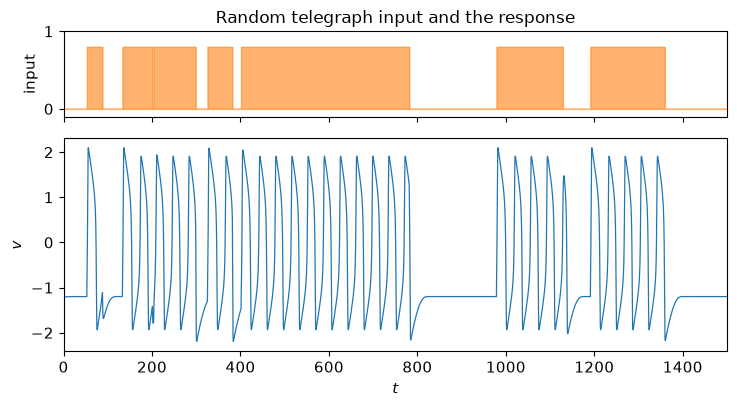

In [11]:
TOTAL = 200000
tr = m.run(keep=False, total=TOTAL)
t, s, v = tr.t, tr["s"], tr["v"]
fig, axs = plt.subplots(2, 1, figsize=(7.5, 4.2), sharex=True, gridspec_kw={"height_ratios": [1, 2.5]})
n = int(1500 / 0.05)
axs[0].fill_between(t[:n], tr["input"][:n], step="post", color="tab:orange", alpha=0.6)
axs[0].set(ylabel="input", ylim=(-0.1, 1), title="Random telegraph input and the response")
axs[1].plot(t[:n], v[:n], lw=0.9)
axs[1].set(xlabel="$t$", ylabel="$v$", xlim=(0, 1500))
fig.tight_layout()
fig.savefig(FIG / "time_series.png")

### Statistics of the input

The stays in each state are read from the jumps of $s$ (only complete stays;
the ends of the run are dropped). Stays on should be exponential with mean
$1/k_{\mathrm{off}}$ and stays off with mean $1/k_{\mathrm{on}}$: on a log
scale the histograms follow straight lines $k\,e^{-kt}$.

1382 switches; fraction of time on 0.6547; mean stay on 189.5 (691), off 100.0 (690)


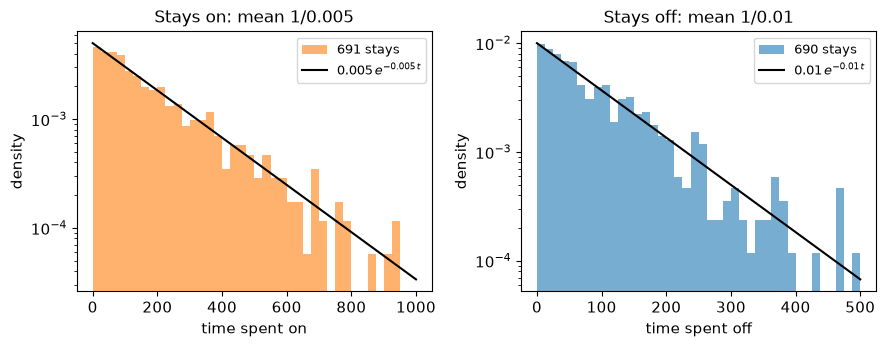

In [12]:
frac_on = s.mean()
jumps = np.flatnonzero(np.diff(s) != 0) + 1
dwell, state = np.diff(t[jumps]), s[jumps[:-1]]
on, off = dwell[state == 1], dwell[state == 0]
print(f"{len(jumps)} switches; fraction of time on {frac_on:.4f};"
      f" mean stay on {on.mean():.1f} ({len(on)}), off {off.mean():.1f} ({len(off)})")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, d, k, lab, col in ((axs[0], on, koff, "on", "tab:orange"), (axs[1], off, kon, "off", "tab:blue")):
    ax.hist(d, bins=40, range=(0, 5 / k), density=True, color=col, alpha=0.6, label=f"{len(d)} stays")
    x = np.linspace(0, 5 / k, 200)
    ax.plot(x, k * np.exp(-k * x), "k-", lw=1.5, label=rf"${k}\,e^{{-{k}\,t}}$")
    ax.set(yscale="log", xlabel=f"time spent {lab}", ylabel="density", title=f"Stays {lab}: mean $1/{k}$")
    ax.legend()
fig.tight_layout()
fig.savefig(FIG / "dwell_times.png")

### The noise-free model: rest at input 0, oscillation at input 0.8

As in section 01, the Hopf points of FitzHugh–Nagumo are where the trace
$1 - v^2 - \varepsilon b$ vanishes, at $v = \mp c$ with
$c = \sqrt{1 - \varepsilon b}$, and on the curve of equilibria

$$
i = \frac{v^3}{3} - v + \frac{v + a}{b} .
$$

We compute the equilibria at constant inputs 0 and 0.8 (switching off the
telegraph term with $\Delta i = 0$), and the period $T$ of the oscillation at
constant input 0.8 (mean over the upward crossings of $v = 1$, first spikes
dropped).

In [13]:
c = np.sqrt(1 - eps * b)
i_hopf = sorted(sg * (c**3 / 3 - c + c / b) + a / b for sg in (-1, 1))
print(f"Hopf range of the input: {i_hopf[0]:.4f} < i < {i_hopf[1]:.4f}")
eqs = {}
for inp, guess in ((i0, (-1.2, -0.6)), (i0 + di, (-0.3, 0.5))):
    m.set(i0=inp, di=0)
    eqs[inp] = m.equilibrium({"v": guess[0], "w": guess[1]})
    print(f"  input {inp}: {eqs[inp]}, eigenvalues {np.round(eqs[inp].eigenvalues, 4)}")
det_run = m.run(keep=False, total=600)
up = det_run.t[1:][(det_run["v"][:-1] < 1) & (det_run["v"][1:] >= 1)]
T = (up[-1] - up[2]) / (len(up) - 3)
m.set(i0=i0, di=di)
print(f"  period of the oscillation at input 0.8: {T:.2f}")

Hopf range of the input: 0.3313 < i < 1.4187


  input 0.0: <Equilibrium stable V=-1.19941, W=-0.62426>, eigenvalues [-0.2513+0.2119j -0.2513-0.2119j]


  input 0.8: <Equilibrium unstable V=-0.272901, W=0.533874>, eigenvalues [0.8367+0.j 0.0248+0.j]


  period of the oscillation at input 0.8: 36.52


### Spikes and the input

A spike starts where $v$ rises through 1. It may start while the input is on,
or just after it went off (the end of a spike already under way); none should
start later than one period $T$ after the input went off. Within one stay on,
the intervals between spikes should equal the noise-free period.

In [14]:
starts = np.flatnonzero((v[:-1] < 1) & (v[1:] >= 1)) + 1
last_on = np.maximum.accumulate(np.where(s == 1, np.arange(len(s)), 0))
late = (s[starts] == 0) & (t[starts] - t[last_on[starts]] > T)
print(f"{len(starts)} spikes: {np.sum(s[starts] == 1)} start while on,"
      f" {np.sum(s[starts] == 0)} just after the input went off, {late.sum()} later than {T:.1f} after")
seg = np.cumsum(np.r_[0, np.diff(s) != 0])
isi = [t[j] - t[i] for i, j in zip(starts[:-1], starts[1:])
       if s[i] == 1 and seg[i] == seg[j]]
print(f"median interval between spikes within a stay on: {np.median(isi):.2f} ({len(isi)} intervals)")

3866 spikes: 3849 start while on, 17 just after the input went off, 0 later than 36.5 after
median interval between spikes within a stay on: 36.50 (3167 intervals)


### Checks

* The fraction of time on is $p = k_{\mathrm{on}}/(k_{\mathrm{on}} + k_{\mathrm{off}})$.
  The time average of a telegraph signal over a run of length $T_{\mathrm{run}}$ has variance
  $2p(1-p)\,\tau_c/T_{\mathrm{run}}$ with correlation time
  $\tau_c = 1/(k_{\mathrm{on}} + k_{\mathrm{off}})$; we allow 4 standard errors.
* The mean stays on and off, $1/k_{\mathrm{off}}$ and $1/k_{\mathrm{on}}$: the
  mean of $N$ exponential stays has standard error $\text{mean}/\sqrt N$
  (4 allowed). For an exponential the standard deviation equals the mean.
* The rest state is stable at input 0 and unstable at 0.8; 0.8 lies inside the
  Hopf range and 0 below it; at input 0.8 the sum of the eigenvalues is the
  trace $1 - v^2 - \varepsilon b$.
* No spike starts later than one period after the input went off, and the
  median interval between spikes while on is the noise-free period (spike times
  are resolved to the step $dt = 0.05$, so to about $2\,dt$).

In [15]:
p = kon / (kon + koff)
check("fraction of time on kon/(kon+koff)", frac_on, p, 4 * np.sqrt(2 * p * (1 - p) / (kon + koff) / TOTAL))
check("mean stay on 1/koff", on.mean(), 1 / koff, 4 / koff / np.sqrt(len(on)))
check("mean stay off 1/kon", off.mean(), 1 / kon, 4 / kon / np.sqrt(len(off)))
check("stays on: std/mean = 1 (exponential)", on.std() / on.mean(), 1, 4 / np.sqrt(len(on)))
check("rest state stable at input 0 (1 = yes)", float(eqs[i0].stable), 1, 0)
check("rest state unstable at input 0.8 (1 = yes)", float(not eqs[i0 + di].stable), 1, 0)
check("input 0.8 inside the Hopf range (1 = yes)", float(i_hopf[0] < i0 + di < i_hopf[1]), 1, 0)
check("input 0 below the Hopf range (1 = yes)", float(i0 < i_hopf[0]), 1, 0)
v8 = eqs[i0 + di].x["V"]
check("trace at input 0.8 = 1 - v^2 - eps*b (exact)", float(np.sum(eqs[i0 + di].eigenvalues).real),
      1 - v8**2 - eps * b, 1e-5)
check("spikes starting later than one period after the input went off", late.sum(), 0, 0)
check("interval between spikes while on = noise-free period", np.median(isi), T, 0.1)
checks_done()

  ok   fraction of time on kon/(kon+koff): 0.654715 (expected 0.666667)
  ok   mean stay on 1/koff: 189.498 (expected 200)
  ok   mean stay off 1/kon: 99.979 (expected 100)
  ok   stays on: std/mean = 1 (exponential): 0.97024 (expected 1)
  ok   rest state stable at input 0 (1 = yes): 1 (expected 1)
  ok   rest state unstable at input 0.8 (1 = yes): 1 (expected 1)
  ok   input 0.8 inside the Hopf range (1 = yes): 1 (expected 1)
  ok   input 0 below the Hopf range (1 = yes): 1 (expected 1)
  ok   trace at input 0.8 = 1 - v^2 - eps*b (exact): 0.861525 (expected 0.861525)
  ok   spikes starting later than one period after the input went off: 0 (expected 0)
  ok   interval between spikes while on = noise-free period: 36.5 (expected 36.5179)

27_telegraph-fhn-markov: 11/11 checks passed


<a id="fhn-chain-arrays"></a>
## 28. A chain of FitzHugh–Nagumo cells: travelling waves

Twenty FitzHugh–Nagumo cells in a line, each coupled to its neighbours by
diffusion of $v$ with strength $d$:

$$
\dot v_j = v_j - \frac{v_j^3}{3} - w_j + i_1\,\delta_{j1} + d\,(v_{j+1} - 2v_j + v_{j-1}),
\qquad \dot w_j = \varepsilon\,(v_j + a - b\,w_j),
$$

for $j = 1, \dots, 20$, with no-flux ends $v_0 = v_1$, $v_{21} = v_{20}$.
Only cell 1 gets the input $i_1 = 1$ (written as $i_1\,H(1.5 - j)$ with the
Heaviside step $H$), and it fires repeatedly; each spike travels down the chain
as a wave. Parameters: $d = 1$, $\varepsilon = 0.08$, $a = 0.7$, $b = 0.8$.

We draw the space-time picture of the waves, compare the firing period at the
two ends, and measure the wave speed against the coupling $d$. For a wide
front the chain behaves like a cable, $v_t = d\,v_{xx} + \dots$, whose wave
speed grows like $\sqrt d$.

In [16]:
section("28_fhn-chain-arrays")

### The model

The model uses XPP's arrays: `begin_block("1..20")` … `end_block()` writes
`%[1..20] ... %`, which repeats the lines with `[j]` = 1, 2, …, 20, and
`w[1..20]` does the same for a single line. `crossings(tr, col)` returns the
times where a column rises through a level, interpolated between output steps.

In [17]:
N = 20
mb = (ModelBuilder("fhn_chain")
      .comment("A chain of 20 diffusively coupled FitzHugh-Nagumo cells")
      .begin_block("1..20")
      .ode("v[j]", "v[j]-v[j]^3/3-w[j]+i1*heav(1.5-[j])+d*(v[j+1]-2*v[j]+v[j-1])")
      .end_block()
      .ode("w[1..20]", "eps*(v[j]+a-b*w[j])")
      .fixed("v0", "v1")
      .fixed("v21", "v20")
      .parameter(i1=1, d=1, eps=0.08, a=0.7, b=0.8)
      .initial({"v[1..20]": -1.2})
      .initial({"w[1..20]": -0.62})
      .option(total=200, dt=0.05))
print(mb.render())
m = mb.load(ODE)
cells = [f"v{j}" for j in range(1, N + 1)]


def crossings(tr, col, level=0.0):
    x, t = tr[col], tr.t
    k = np.flatnonzero((x[:-1] < level) & (x[1:] >= level))
    return t[k] + (level - x[k]) / (x[k + 1] - x[k]) * (t[k + 1] - t[k])

# A chain of 20 diffusively coupled FitzHugh-Nagumo cells
%[1..20]
v[j]'=v[j]-v[j]^3/3-w[j]+i1*heav(1.5-[j])+d*(v[j+1]-2*v[j]+v[j-1])
%
w[1..20]'=eps*(v[j]+a-b*w[j])
v0=v1
v21=v20
par i1=1,d=1,eps=0.08,a=0.7,b=0.8
init v[1..20]=-1.2
init w[1..20]=-0.62
@ total=200,dt=0.05
done



### Space-time picture at $d = 1$

Each row is one cell's voltage against time: the waves are the slanted
stripes.

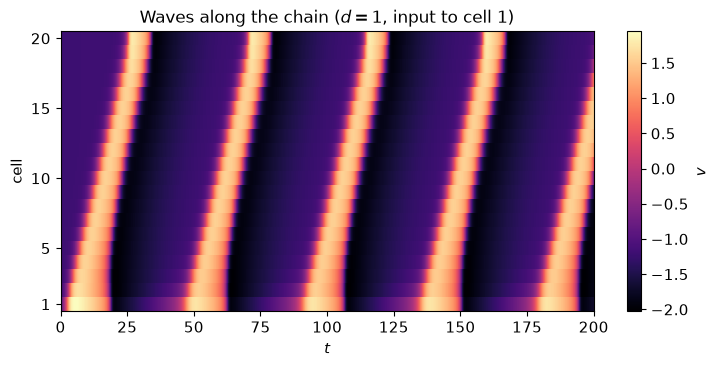

In [18]:
tr = m.run(keep=False, total=200)
V = np.array([tr[c] for c in cells])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(V, aspect="auto", origin="lower", cmap="magma", interpolation="nearest",
               extent=(tr.t[0], tr.t[-1], 0.5, N + 0.5))
fig.colorbar(im, ax=ax, label="$v$")
ax.set(xlabel="$t$", ylabel="cell", yticks=[1, 5, 10, 15, 20],
       title="Waves along the chain ($d = 1$, input to cell 1)")
fig.tight_layout()
fig.savefig(FIG / "space_time.png")

### Firing period at the two ends

Over a longer run, the period at cell 1 and at cell 20 (mean of the last 5
intervals), the transit time of the first wave, and the number of spikes at
cell 1 that had time to arrive at cell 20.

period at cell 1 43.9783, at cell 20 43.9783; transit time 23.19; spikes 18 at cell 1 (with time to arrive), 18 at cell 20


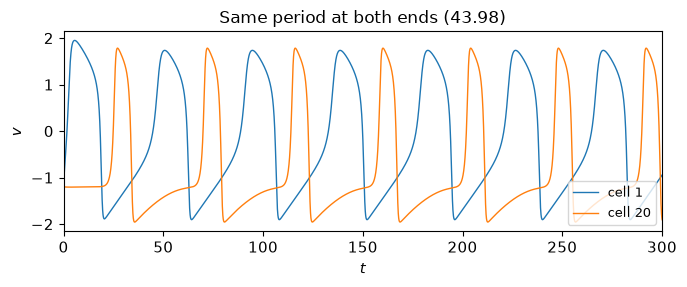

In [19]:
tr = m.run(keep=False, total=800)
sp1, sp20 = crossings(tr, "v1"), crossings(tr, "v20")
P1, P20 = np.diff(sp1)[-5:].mean(), np.diff(sp20)[-5:].mean()
transit = sp20[0] - sp1[0]
n1 = np.sum(sp1 < tr.t[-1] - transit)
print(f"period at cell 1 {P1:.4f}, at cell 20 {P20:.4f}; transit time {transit:.2f};"
      f" spikes {n1} at cell 1 (with time to arrive), {len(sp20)} at cell 20")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(tr.t, tr["v1"], lw=1, label="cell 1")
ax.plot(tr.t, tr["v20"], lw=1, label="cell 20")
ax.set(xlim=(0, 300), xlabel="$t$", ylabel="$v$", title=f"Same period at both ends ({P1:.2f})")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "ends.png")

### Wave speed against the coupling

With no input ($i_1 = 0$), a single wave is started by kicking cells 1–3 to
$v = 2$, and timed across cells 5 to 16, away from the kick and from the far
end. A straight-line fit of arrival time against cell number gives the time per
cell, whose inverse is the speed; `worst` records the largest miss of that
line. A power law $c = A\,d^{\,p}$ is fitted over $d \ge 2$, where the front
spans several cells.

   d    speed   speed/sqrt(d)
   0.2  0.2770  0.6195
   0.3  0.3791  0.6921
   0.5  0.5267  0.7449
   0.7  0.6412  0.7663
   1.0  0.7818  0.7818
   1.5  0.9720  0.7937
   2.0  1.1312  0.7999
   3.0  1.3974  0.8068
   4.0  1.6218  0.8109
   6.0  1.9980  0.8157
   8.0  2.3124  0.8176
power law over d >= 2: speed = 0.7922 d^0.5159


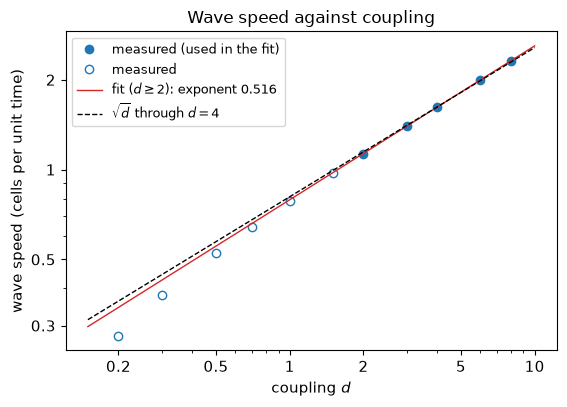

In [20]:
from matplotlib.ticker import FormatStrFormatter, NullFormatter

D = np.array([0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 4, 6, 8])
kick = {f"v{j}": 2.0 for j in (1, 2, 3)}
speed, worst = [], []
for d in D:
    tr = m.run(keep=False, d=d, i1=0, total=150, **kick)
    js = np.arange(5, 17)
    arrive = np.array([crossings(tr, f"v{j}")[0] for j in js])
    slope, icpt = np.polyfit(js, arrive, 1)
    speed.append(1 / slope)
    worst.append(np.abs(arrive - (slope * js + icpt)).max())
speed, worst = np.array(speed), np.array(worst)
fit = D >= 2
p, logA = np.polyfit(np.log(D[fit]), np.log(speed[fit]), 1)
print("   d    speed   speed/sqrt(d)")
for d, c in zip(D, speed):
    print(f"  {d:4.1f}  {c:.4f}  {c / np.sqrt(d):.4f}")
print(f"power law over d >= 2: speed = {np.exp(logA):.4f} d^{p:.4f}")

fig, ax = plt.subplots(figsize=(5.8, 4.2))
ax.loglog(D[fit], speed[fit], "o", color="tab:blue", label="measured (used in the fit)")
ax.loglog(D[~fit], speed[~fit], "o", mfc="none", color="tab:blue", label="measured")
dd = np.geomspace(0.15, 10, 50)
ax.loglog(dd, np.exp(logA) * dd**p, "-", color="tab:red", lw=1, label=rf"fit ($d \geq 2$): exponent {p:.3f}")
ax.loglog(dd, speed[D == 4][0] * np.sqrt(dd / 4), "k--", lw=1, label=r"$\sqrt{d}$ through $d = 4$")
ax.set(xlabel="coupling $d$", ylabel="wave speed (cells per unit time)", title="Wave speed against coupling")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FormatStrFormatter("%g"))
    axis.set_minor_formatter(NullFormatter())
ax.set_yticks([0.3, 0.5, 1, 2])
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10])
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "speed_vs_d.png")

### Checks

* The period at cell 20 equals the period at cell 1 (interpolated crossing
  times are good to well under 0.01 with $dt = 0.05$), and every spike that
  had time to arrive reaches cell 20.
* A wave at constant speed arrives on a straight line in (cell, $t$): at
  $d = 1$ the largest miss is within an output step.
* In the cable limit the speed is $c = c_*\sqrt d$, so the fitted exponent
  should be $p = 1/2$. On the lattice, $c/\sqrt d$ still creeps up towards
  $c_*$ with $d$ (the front spans only a few cells); over $d = 2, \dots, 8$ the
  table shows a drift of about 2%, which raises the fitted exponent by about
  0.02: we allow 0.03.

In [21]:
check("period at cell 20 = period at cell 1", P20, P1, 0.01)
check("every spike reaches cell 20 (spike counts)", len(sp20), n1, 0)
check("constant speed: largest miss of a straight line in t (d = 1)", worst[D == 1][0], 0, 0.05)
check("power-law exponent of speed against d", p, 0.5, 0.03)
checks_done()

  ok   period at cell 20 = period at cell 1: 43.9783 (expected 43.9783)
  ok   every spike reaches cell 20 (spike counts): 18 (expected 18)
  ok   constant speed: largest miss of a straight line in t (d = 1): 0.0277528 (expected 0)
  ok   power-law exponent of speed against d: 0.515883 (expected 0.5)

28_fhn-chain-arrays: 4/4 checks passed


## Summary

All checks of this notebook:

In [22]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

26_noisy-fhn-sde                           8/8
27_telegraph-fhn-markov                   11/11
28_fhn-chain-arrays                        4/4

23/23 checks passed
